# Praktikum 2 - Eksperimen Hyperparameter dan Evaluasi HDBSCAN

**Mata Kuliah:** Pembelajaran Mesin
**Jobsheet 05:** Klasterisasi Hierarki

### Tujuan Praktikum:
1. Menganalisis pengaruh parameter `min_cluster_size` terhadap ukuran dan jumlah klaster yang dihasilkan.
2. Menganalisis pengaruh parameter `min_samples` terhadap toleransi deteksi noise/outliers.
3. Mengevaluasi hasil klasterisasi menggunakan **Silhouette Score** dan **Davies-Bouldin Index (DBI)**.

## Langkah 1 - Import Library dan Persiapan Data

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.metrics import silhouette_score, davies_bouldin_score
try:
    from sklearn.cluster import HDBSCAN
except ImportError:
    import hdbscan
    HDBSCAN = hdbscan.HDBSCAN

centers = [[1, 1], [-1, -1], [1.5, -1.5]]
X, labels_true = make_blobs(
    n_samples=750, centers=centers, cluster_std=[0.4, 0.1, 0.75], random_state=0
)

def plot(X, labels, probabilities=None, parameters=None, ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(10, 4))
    labels = labels if labels is not None else np.ones(X.shape[0])
    probabilities = probabilities if probabilities is not None else np.ones(X.shape[0])
    unique_labels = set(labels)
    colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]
    proba_map = {idx: probabilities[idx] for idx in range(len(labels))}
    for k, col in zip(unique_labels, colors):
        if k == -1:
            col = [0, 0, 0, 1]
        class_index = (labels == k).nonzero()[0]
        for ci in class_index:
            ax.plot(
                X[ci, 0], X[ci, 1],
                'x' if k == -1 else 'o',
                markerfacecolor=tuple(col),
                markeredgecolor='k',
                markersize=4 if k == -1 else 1 + 5 * proba_map[ci],
            )
    n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
    title = f'Estimated clusters: {n_clusters_}'
    if parameters is not None:
        title += ' | ' + ', '.join(f'{k}={v}' for k, v in parameters.items())
    ax.set_title(title)

## Langkah 2 - Eksperimen Hyperparameter `min_cluster_size`
Menguji nilai `min_cluster_size`: 5, 15, dan 35. Semakin besar nilainya, semakin sedikit klaster kecil yang terbentuk.

C:\Users\luvma\anaconda3\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


C:\Users\luvma\anaconda3\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


C:\Users\luvma\anaconda3\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


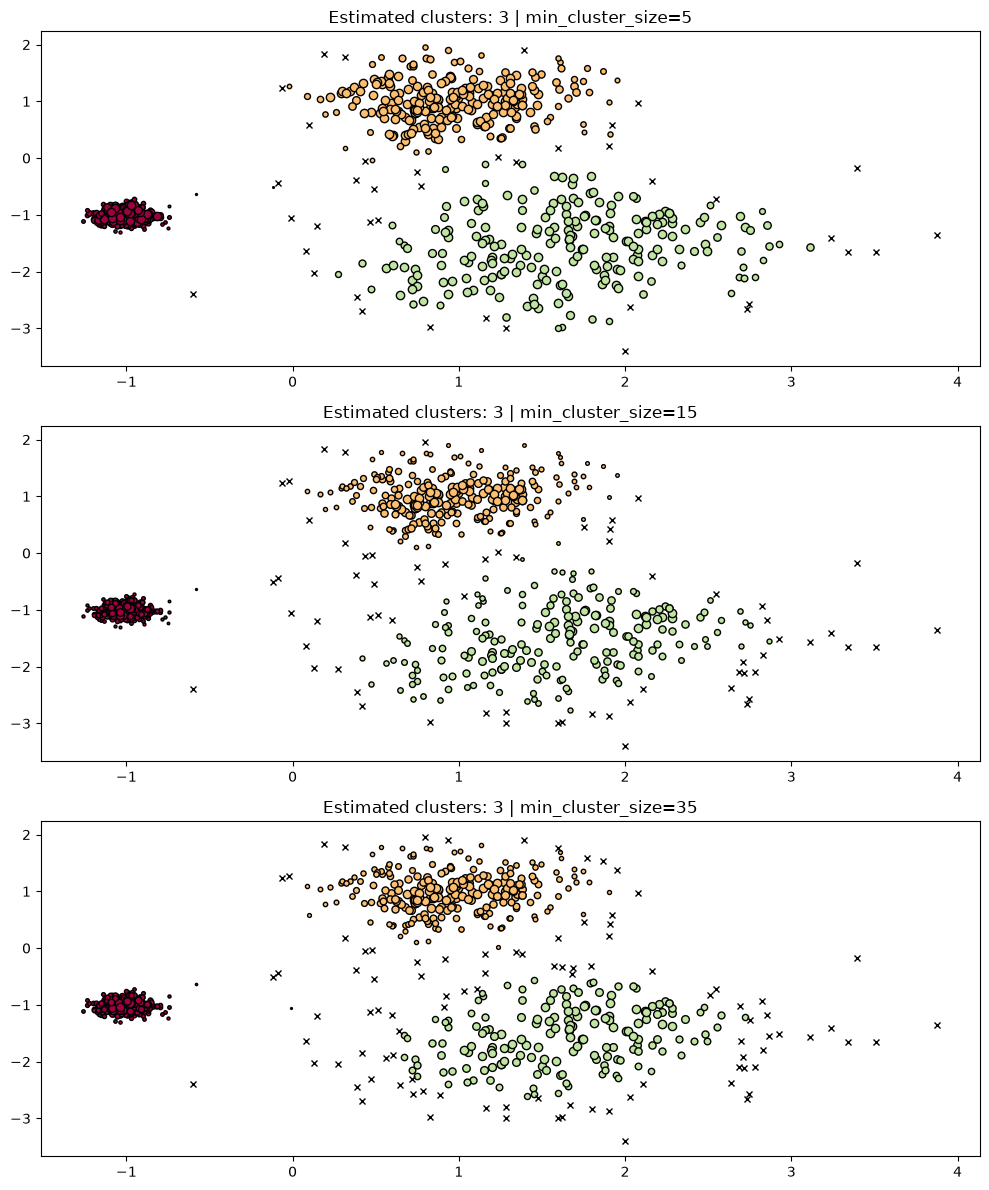

In [2]:
PARAM_MCS = [{'min_cluster_size': 5}, {'min_cluster_size': 15}, {'min_cluster_size': 35}]
fig, axes = plt.subplots(3, 1, figsize=(10, 12))
for i, param in enumerate(PARAM_MCS):
    hdb = HDBSCAN(**param).fit(X)
    plot(X, hdb.labels_, hdb.probabilities_, param, ax=axes[i])
plt.tight_layout()
plt.show()

## Langkah 3 - Eksperimen Hyperparameter `min_samples`
Parameter `min_samples` mengontrol seberapa konservatif pengelompokan terhadap noise. Nilai yang lebih besar menjadikan algoritma lebih ketat dan menghasilkan lebih banyak titik noise.

C:\Users\luvma\anaconda3\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


C:\Users\luvma\anaconda3\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(
C:\Users\luvma\anaconda3\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


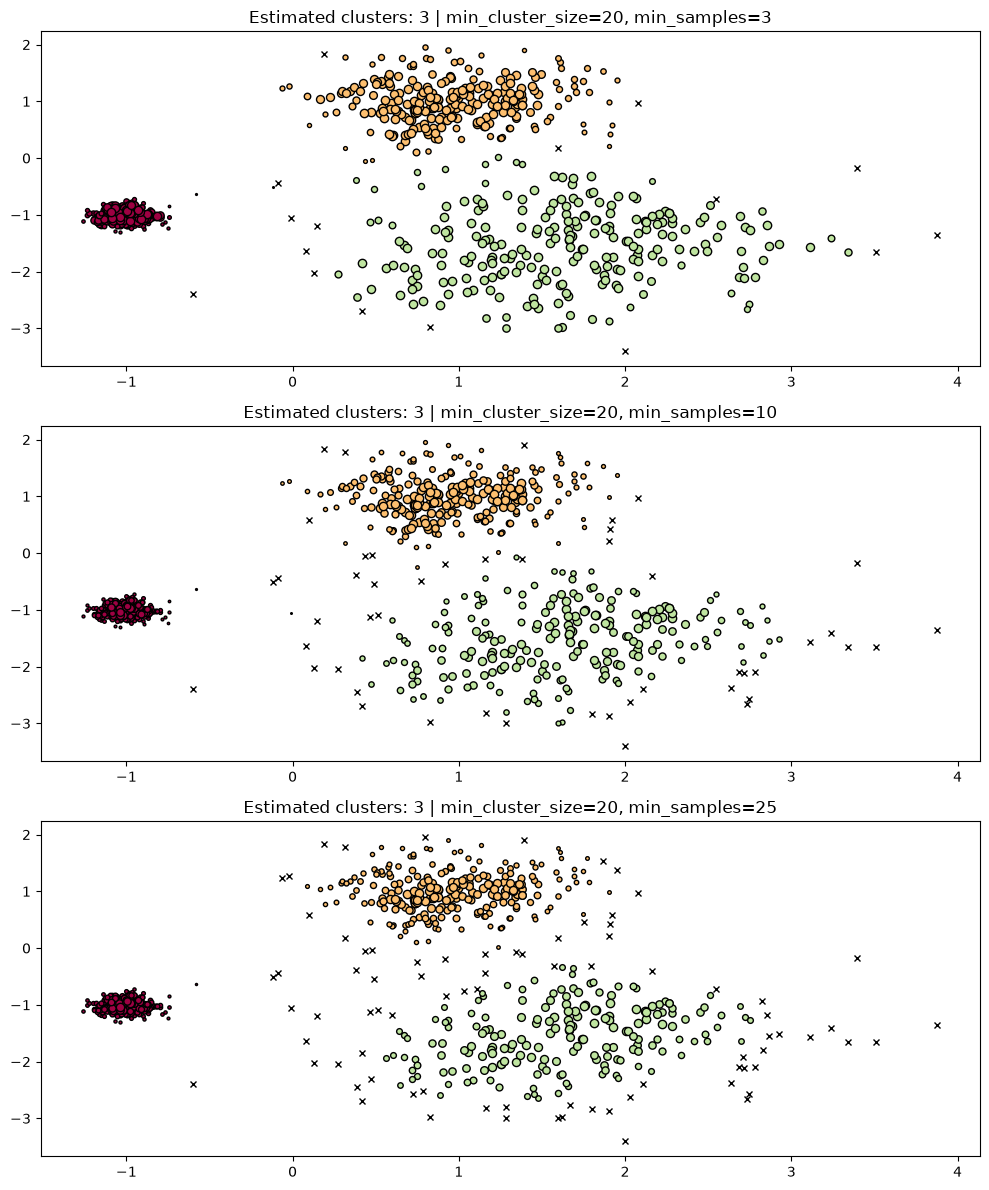

In [3]:
PARAM_MS = [
    {'min_cluster_size': 20, 'min_samples': 3},
    {'min_cluster_size': 20, 'min_samples': 10},
    {'min_cluster_size': 20, 'min_samples': 25},
]
fig, axes = plt.subplots(3, 1, figsize=(10, 12))
for i, param in enumerate(PARAM_MS):
    hdb = HDBSCAN(**param).fit(X)
    plot(X, hdb.labels_, hdb.probabilities_, param, ax=axes[i])
plt.tight_layout()
plt.show()

## Langkah 4 - Evaluasi Kualitas Klasterisasi (Silhouette Score & Davies-Bouldin Index)
- **Silhouette Score**: Rentang -1 hingga 1 (Mendekati 1 = klaster padat dan terpisah sangat baik).
- **Davies-Bouldin Index (DBI)**: Nilai non-negatif (Semakin kecil = semakin baik dan terpisah).

Silhouette Score:      0.6499
Davies-Bouldin Index:  3.5561


C:\Users\luvma\anaconda3\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


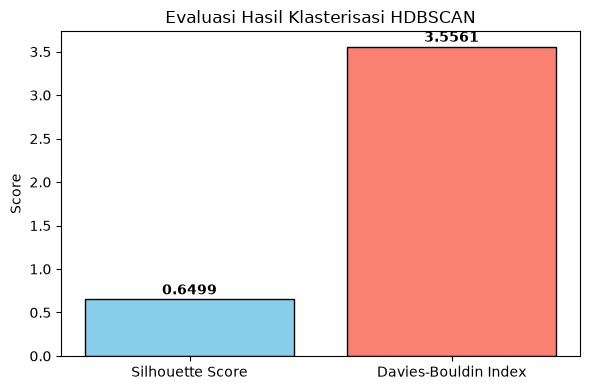

In [4]:
best_hdb = HDBSCAN(min_cluster_size=20, min_samples=10).fit(X)
sil_score = silhouette_score(X, best_hdb.labels_)
dbi_score = davies_bouldin_score(X, best_hdb.labels_)

print(f'Silhouette Score:      {sil_score:.4f}')
print(f'Davies-Bouldin Index:  {dbi_score:.4f}')

# Visualisasi diagram batang metrik evaluasi
scores = {'Silhouette Score': sil_score, 'Davies-Bouldin Index': dbi_score}
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(scores.keys(), scores.values(), color=['skyblue', 'salmon'], edgecolor='k')
for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + 0.02, f'{yval:.4f}', ha='center', va='bottom', fontweight='bold')
ax.set_title('Evaluasi Hasil Klasterisasi HDBSCAN')
ax.set_ylabel('Score')
plt.tight_layout()
plt.show()